In [5]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from torchvision import transforms
from src.data.dataset import MVTecDataset

Calculating mean and std for bottle category
Values to normalize the bottle category:
Mean: [0.5354132056236267, 0.531684160232544, 0.5479597449302673]
Std: [0.3656117916107178, 0.3659615218639374, 0.34921830892562866]


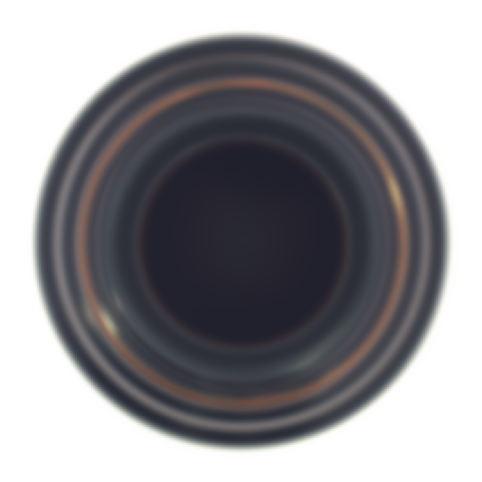

In [6]:
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

root_dir = 'D:/Unsupervised-Anomaly-Detection-Using-Autoencoder-Architecture/data'
category = 'bottle'

train_dataset = MVTecDataset(
    root_dir=root_dir,
    category=category,
    mode='train',
    transform=transform)

print(f'Calculating mean and std for {category} category')
pixel_sum = torch.zeros(3)
pixel_sum_sq = torch.zeros(3)
num_pixels = 0
avg_image = torch.zeros((3, 256, 256))

for img, _, _, _ in train_dataset:
    pixel_sum += img.sum(dim=[1, 2])
    pixel_sum_sq += (img ** 2).sum(dim=[1, 2])
    num_pixels += img.shape[1] * img.shape[2]

    avg_image += img

mean = pixel_sum / num_pixels
std = torch.sqrt((pixel_sum_sq / num_pixels) - (mean ** 2))
avg_image /= len(train_dataset)

print(f'Values to normalize the {category} category:')
print(f'Mean: {mean.tolist()}')
print(f'Std: {std.tolist()}')

plt.figure(figsize=(6, 6))
plt.imshow(avg_image.permute(1, 2, 0).numpy())
plt.axis('off')
plt.show()

### EDA Conclusions: Normalization & Spatial Stability
* **Custom Normalization Required:** The calculated RGB statistics for the bottle category (Mean: ~[0.54, 0.53, 0.55], Std: ~[0.37, 0.37, 0.35]) deviate from standard ImageNet values, requiring these specific weights in the preprocessing pipeline.
* **Spatial Variance:** The averaged dataset image displays a clearly centered circular structure with only minor edge blurring. This strong spatial alignment indicates that aggressive geometric augmentations are unnecessary, allowing the autoencoder to dedicate its latent capacity to reconstructing surface-level textures rather than spatial variations.
---

Analysing distribution and characteristics of anomalies in bottle category


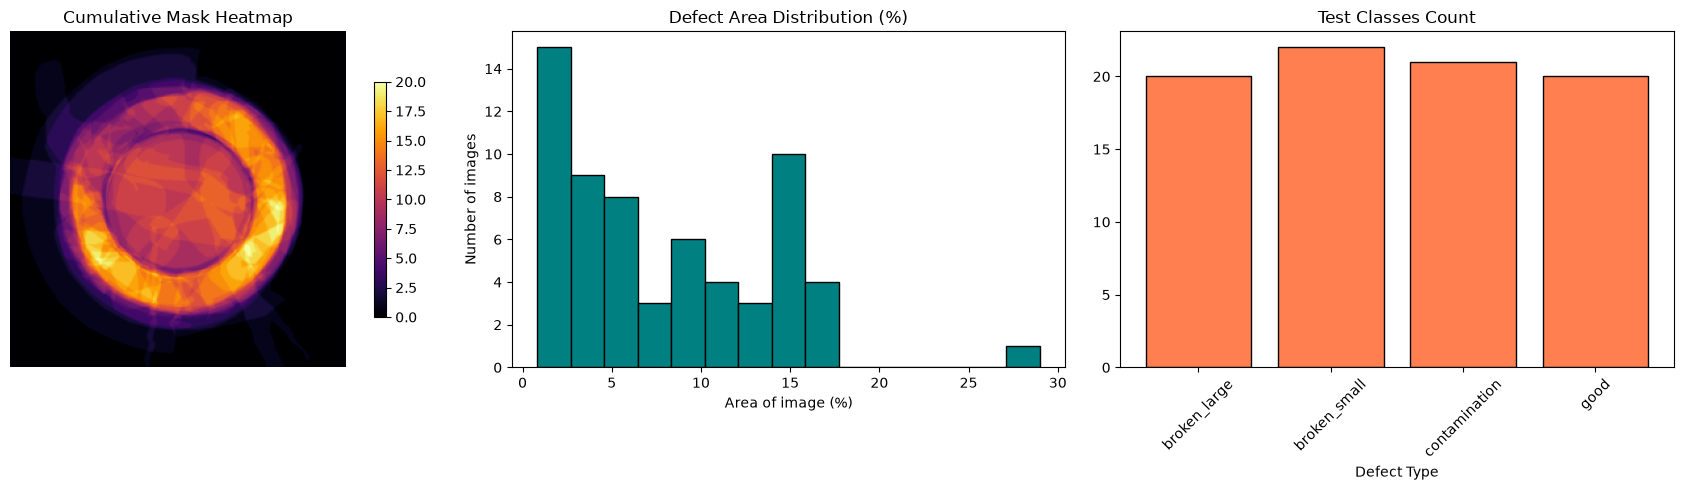

Average defect area percentage: 8.17%
Max defect area percentage: 29.00%
Min defect area percentage: 0.82%


In [7]:
test_dataset = MVTecDataset(
    root_dir=root_dir,
    category=category,
    mode='test',
    transform=transform,
    mask_transform=transform
)

print(f'Analysing distribution and characteristics of anomalies in {category} category')
cumulative_mask = torch.zeros((256, 256))
mask_areas_pct = []
defect_counts = {}

for image, mask, label, path in test_dataset:
    defect_type = Path(path).parent.name
    defect_counts[defect_type] = defect_counts.get(defect_type, 0) + 1

    if label == 1:
        mask_sq = mask.squeeze(0)       # Remove channel dimension
        cumulative_mask += mask_sq
        area_pct = (mask_sq > 0).float().mean().item() * 100        # Calculate the percentage of size of anomaly in the image
        mask_areas_pct.append(area_pct)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im = axes[0].imshow(cumulative_mask.numpy(), cmap='inferno')
axes[0].set_title('Cumulative Mask Heatmap')
axes[0].axis('off')
fig.colorbar(im, ax=axes[0], shrink=0.7)

axes[1].hist(mask_areas_pct, bins=15, color='teal', edgecolor='black')
axes[1].set_title('Defect Area Distribution (%)')
axes[1].set_xlabel('Area of image (%)')
axes[1].set_ylabel('Number of images')

classes = list(defect_counts.keys())
counts = list(defect_counts.values())
axes[2].bar(classes, counts, color='coral', edgecolor='black')
axes[2].set_title('Test Classes Count')
axes[2].set_xlabel('Defect Type')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(f'Average defect area percentage: {np.mean(mask_areas_pct):.2f}%')
print(f'Max defect area percentage: {np.max(mask_areas_pct):.2f}%')
print(f'Min defect area percentage: {np.min(mask_areas_pct):.2f}%')

### EDA Conclusions: Defect Characteristics
* **Spatial Distribution:** The cumulative mask heatmap demonstrates that anomalies are not randomly scattered but concentrated in a specific, ring-like area along the edges of the object. This requires the network to focus heavily on precisely reconstructing this outer geometry.
* **Defect Size:** The vast majority of defects are small, with the minimum defect covering only 0.82% of the image area and an average size of 8.17%. While large anomalies up to 29.00% occur sporadically, the dominance of tiny defects necessitates a strict dimensionality reduction (narrow bottleneck) in the architecture. This prevents the model from retaining enough capacity to simply encode and reconstruct these micro-anomalies.
* **Test Set Balance:** The representation of test classes is even, with `broken_large`, `broken_small`, `contamination`, and `good` categories containing approximately 20 samples each. This balanced distribution ensures a reliable, unbiased foundation for calculating objective evaluation metrics such as ROC AUC.